In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

In [3]:
iris = load_iris()

X = iris.data
y = iris.target

In [4]:
feature_names = iris.feature_names
class_names = iris.target_names

In [5]:
print("Dataset shape:", X.shape)
print("Number of classes:", len(class_names))
print("Features:", feature_names)
print("Classes:", class_names)

Dataset shape: (150, 4)
Number of classes: 3
Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classes: ['setosa' 'versicolor' 'virginica']


In [6]:
df = pd.DataFrame(X, columns=feature_names)
df["Species"] = [class_names[i] for i in y]

display(df.head(10))
print("\nClass distribution:")
print(df["Species"].value_counts())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
5,5.4,3.9,1.7,0.4,setosa
6,4.6,3.4,1.4,0.3,setosa
7,5.0,3.4,1.5,0.2,setosa
8,4.4,2.9,1.4,0.2,setosa
9,4.9,3.1,1.5,0.1,setosa



Class distribution:
Species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


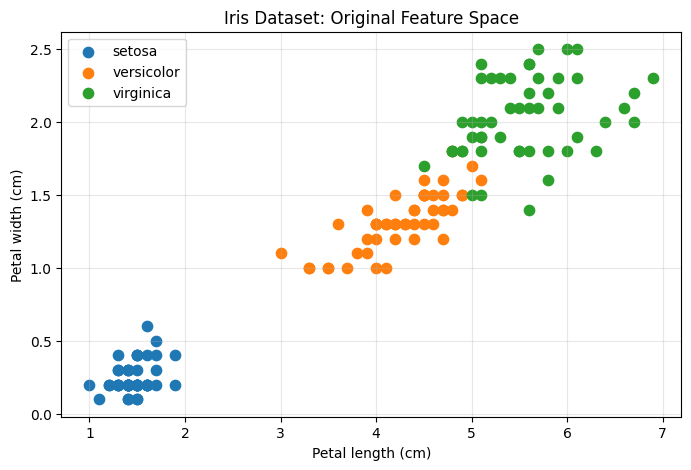

In [7]:
plt.figure(figsize=(8, 5))

for i, name in enumerate(class_names):
    plt.scatter(
        X[y == i, 2],
        X[y == i, 3],
        label=name,
        s=55
    )

plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.title("Iris Dataset: Original Feature Space")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [9]:
# standardization

scaler_vis = StandardScaler()
X_scaled = scaler_vis.fit_transform(X)

print("Original dimensions:", X.shape)
print("Standardized dimensions:", X_scaled.shape)
print("Mean of standardized features:")
print(np.round(X_scaled.mean(axis=0), 3))

Original dimensions: (150, 4)
Standardized dimensions: (150, 4)
Mean of standardized features:
[-0. -0. -0. -0.]


In [10]:
# pca

pca_vis = PCA(n_components=2)
X_pca = pca_vis.fit_transform(X_scaled)

print("Shape after PCA:", X_pca.shape)

print("\nExplained variance ratio:")
print(np.round(pca_vis.explained_variance_ratio_, 4))

print(
    "\nTotal variance retained:",
    round(pca_vis.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

Shape after PCA: (150, 2)

Explained variance ratio:
[0.7296 0.2285]

Total variance retained: 95.81 %


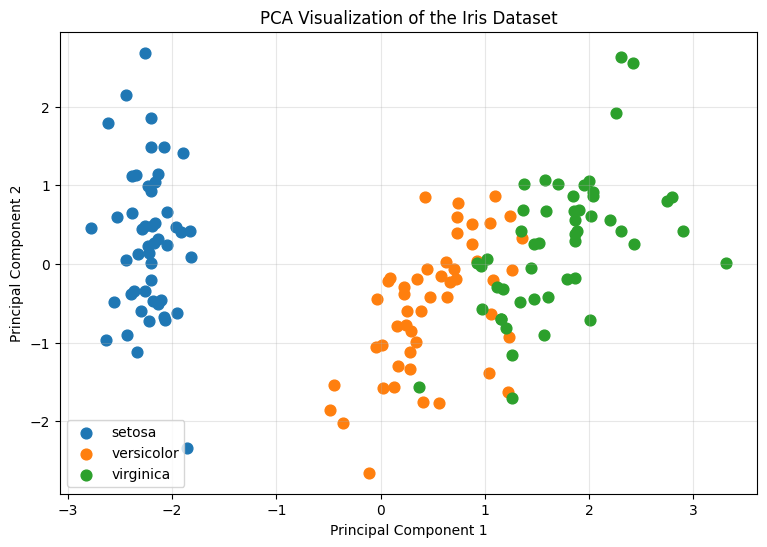

In [11]:
# visualization

plt.figure(figsize=(9, 6))

for i, name in enumerate(class_names):
    plt.scatter(
        X_pca[y == i, 0],
        X_pca[y == i, 1],
        label=name,
        s=60
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of the Iris Dataset")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 120
Testing samples: 30


In [14]:
# classification pipelines

models = {"LR - 4D": Pipeline([("scaler", StandardScaler()), ("classifier", LogisticRegression(max_iter=1000))]),
          "LR - 2D": Pipeline([("scaler", StandardScaler()), ("pca", PCA(n_components=2)), ("classifier", LogisticRegression(max_iter=1000))]),
          "SVM - 4D": Pipeline([("scaler", StandardScaler()), ("classifier", SVC(kernel="rbf"))]),
          "SVM - 2D": Pipeline([("scaler", StandardScaler()), ("pca", PCA(n_components=2)), ("classifier", SVC(kernel="rbf"))])}

In [15]:
results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    predictions[name] = y_pred

    results.append({"Model": name, "Accuracy (%)": round(accuracy_score(y_test, y_pred) * 100, 2)})

results_df = pd.DataFrame(results)

display(results_df)


,Model,Accuracy (%)
0,LR - 4D,93.33
1,LR - 2D,90.00
2,SVM - 4D,96.67
3,SVM - 2D,90.00


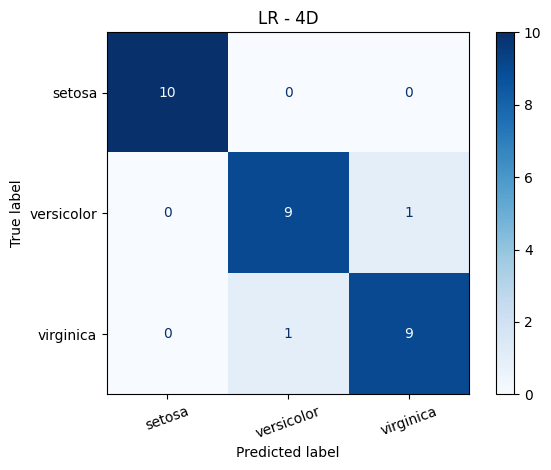

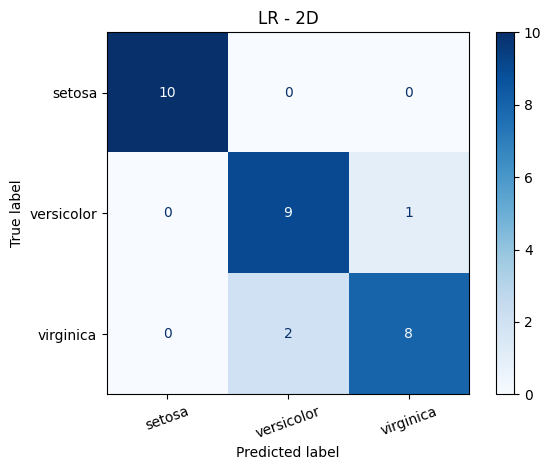

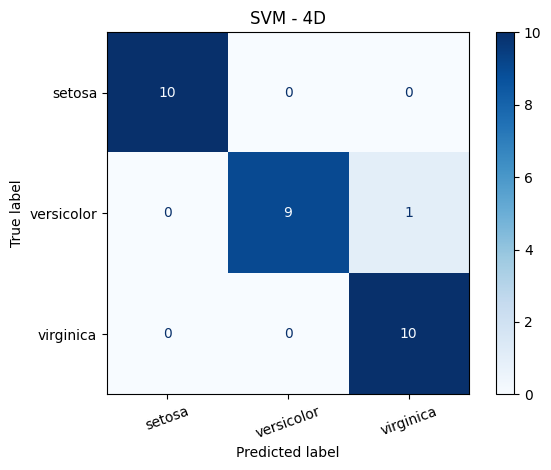

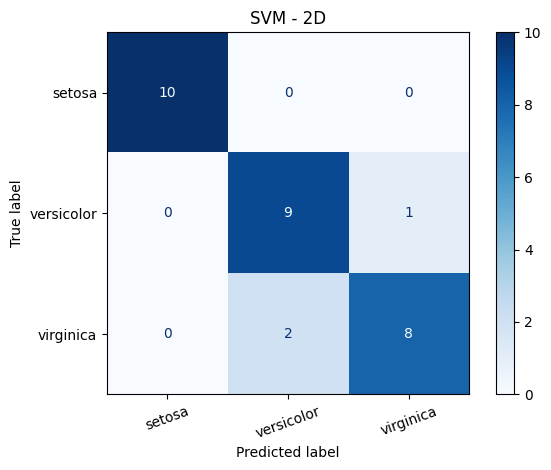

In [16]:
# confusion matrices

for name, y_pred in predictions.items():
    cm = confusion_matrix(y_test, y_pred)

    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

    disp.plot(cmap="Blues", values_format="d")
    plt.title(name)
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()


In [18]:
for name, y_pred in predictions.items():
    print(name)
    print(classification_report(y_test, y_pred, target_names=class_names, zero_division=0))

LR - 4D
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

LR - 2D
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30

SVM - 4D
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95       

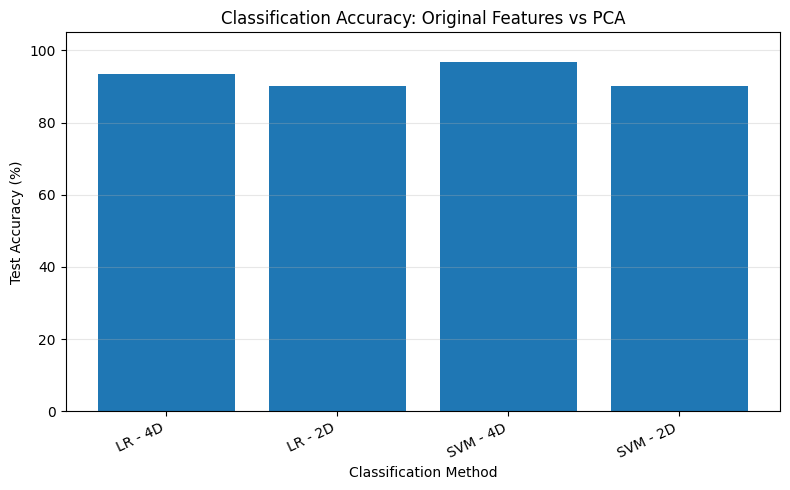

In [20]:
plt.figure(figsize=(8, 5))

plt.bar(results_df["Model"], results_df["Accuracy (%)"])

plt.ylabel("Test Accuracy (%)")
plt.xlabel("Classification Method")
plt.title("Classification Accuracy: Original Features vs PCA")
plt.ylim(0, 105)
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
